# 9. Literatura consultada e implicaciones metodológicas

La revisión integra un inventario de Scopus y Web of Science, una preselección de estudios y una consulta dirigida de textos completos. Los conteos del cribado previo se presentan junto con una auditoría de las exportaciones disponibles. La documentación del inventario presenta limitaciones de trazabilidad en las cadenas originales, los motivos de exclusión por registro y la revisión independiente.

Las extracciones verificadas comprenden Time-MMD, NSW-EPNews, Tan y colaboradores, Lago y colaboradores, REST-TS, TeR-TSF y TimesX. El directorio `literature/` registra versiones, fuentes, huellas y localizadores de resultados. La caracterización de modelos de referencia se fundamenta en su descripción metodológica en texto completo.

In [1]:
%matplotlib inline
from pathlib import Path

ROOT = next(
    directory for directory in [Path.cwd(), *Path.cwd().parents]
    if (directory / "data/manifest.json").exists()
)

from IPython.display import Markdown, display
import json
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
RESULTS = ROOT / 'results'
RESULTS.mkdir(exist_ok=True)
(RESULTS / 'figures').mkdir(exist_ok=True)
(RESULTS / 'tables').mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (11, 4.4), 'figure.dpi': 110, 'savefig.dpi': 160, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.18, 'axes.prop_cycle': plt.cycler(color=['#245b8d', '#d17a32', '#2b8c77', '#8c5da8', '#9a4949'])})
pd.set_option('display.max_rows', 35)
pd.set_option('display.max_columns', 14)
pd.set_option('display.float_format', lambda x: f'{x:.5g}')

In [3]:
def decision(preprocess, architecture, validation, risk):
    display(Markdown('### Implicaciones del análisis\n\n' + '\n'.join(('- **' + a + ':** ' + b for a, b in [('Preprocesamiento', preprocess), ('Arquitectura', architecture), ('Validación', validation), ('Riesgos', risk)]))))

In [4]:
def figure(fig, name):
    fig.tight_layout()
    fig.savefig(RESULTS / 'figures' / (name + '.png'), bbox_inches='tight')
    plt.show()
    plt.close(fig)

In [5]:
def table(frame, name):
    frame.to_csv(RESULTS / 'tables' / (name + '.csv'), index=True)
    display(frame)
    return None

In [6]:
import json
meta = json.loads((ROOT / 'literature/inherited_prisma_counts.json').read_text(encoding='utf-8'))
counts = pd.Series({k: meta[k] for k in ['registros_exportados', 'scopus', 'wos', 'unicos', 'seleccionados']}, name='inventario_previo')
table(counts.to_frame(), 'literatura_inventario_previo')

,inventario_previo
registros_exportados,855
scopus,562
wos,293
unicos,668
seleccionados,83


In [7]:
audit = json.loads((ROOT / 'literature/raw_export_audit.json').read_text(encoding='utf-8'))
table(pd.DataFrame({'exportación_actual': [audit['scopus_current_publication_ids'], audit['wos_current_records']], 'inventario_previo': [audit['inherited_scopus_count'], audit['inherited_wos_count']]}, index=['Scopus', 'Web of Science']), 'literatura_conciliacion_exportaciones')

,exportación_actual,inventario_previo
Scopus,615,562
Web of Science,293,293


In [8]:
display(Markdown(f"La exportación actual de Scopus contiene **{audit['scopus_current_publication_ids']}** identificadores distintos, mientras el inventario previo registra **{audit['inherited_scopus_count']}**. La diferencia de **{audit['scopus_difference']}** registros no está conciliada por artículo. El inventario previo y la exportación actual se presentan por separado hasta completar su conciliación."))

La exportación actual de Scopus contiene **615** identificadores distintos, mientras el inventario previo registra **562**. La diferencia de **53** registros no está conciliada por artículo. El inventario previo y la exportación actual se presentan por separado hasta completar su conciliación.

In [9]:
selected = pd.read_csv(ROOT / 'literature/inherited_selected_83.csv')
freq = selected[['LSTM', 'GRU', 'RNN', 'MLP', 'CNN']].sum().to_frame('resúmenes_preseleccionados_que_mencionan_arquitectura')
table(freq, 'literatura_menciones_no_baselines')

,resúmenes_preseleccionados_que_mencionan_arquitectura
LSTM,24
GRU,7
RNN,5
MLP,7
CNN,7


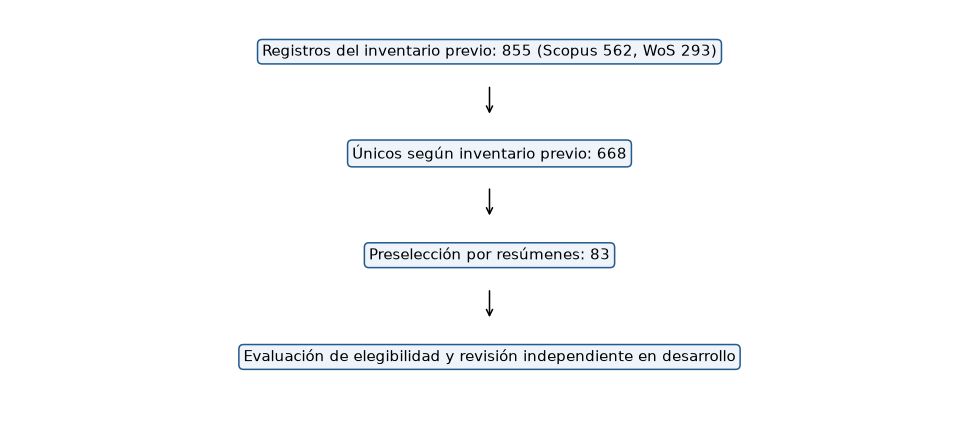

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.axis('off')
boxes = [(0.9, f"Registros del inventario previo: {meta['registros_exportados']} (Scopus {meta['scopus']}, WoS {meta['wos']})"), (0.65, f"Únicos según inventario previo: {meta['unicos']}"), (0.4, f"Preselección por resúmenes: {meta['seleccionados']}"), (0.15, 'Evaluación de elegibilidad y revisión independiente en desarrollo')]
for y, label in boxes:
    ax.text(0.5, y, label, ha='center', va='center', bbox=dict(boxstyle='round', fc='#eef4fa', ec='#245b8d'))
for y in [0.82, 0.57, 0.32]:
    ax.annotate('', xy=(0.5, y - 0.08), xytext=(0.5, y), arrowprops=dict(arrowstyle='->'))
figure(fig, 'flujo_bibliografico_parcial')

## Resultados extraídos de los estudios

La tabla sintetiza resultados publicados junto con su problema, conjunto de datos, modelos y métricas. Las diferencias de escala, frecuencia, horizonte y protocolo requieren interpretar cada resultado en su contexto experimental.


In [11]:
verified = pd.read_csv(ROOT / 'literature/verified_extracts.csv')
table(verified, 'literatura_resultados_verificados')

,referencia,problema,dataset,modelos_comparados_verificados,metrica,valores_reportados,localizador,url,limite_de_comparabilidad
0,"Liu et al. (2024), Time-MMD",Pronóstico multimodal,Energy: gasolina semanal,DLinear uni/multimodal; otros backbones,MSE,H=12: 0.26 unimodal; 0.22 multimodal,"Tabla 12, p.33 del PDF v2",https://arxiv.org/pdf/2406.08627v2,Escala del benchmark; no COP ni precio eléctrico.
1,Tan et al. (2024),Ablación del LLM sobre series numéricas,ETTh1; promedio de horizontes de la tabla,Time-LLM; sin LLM; atención; Transformer,MSE,Time-LLM 0.417; sin LLM 0.405,"Tabla 3, p.6 del PDF v2",https://arxiv.org/pdf/2406.16964v2,No evalúa añadir noticias exógenas; no demuest...
2,"Bi et al. (2025), NSW-EPNews",Pronóstico de precio eléctrico con texto/clima,NSW 2015–2024; subconjunto reciente 50%,ARIMA; LR; XGBoost; ChatGPT-4o; Gemini 1.5 Pro,MAE,ARIMA 54.579; ChatGPT-4o zero-shot 53.646; abl...,"Tabla 2, p.7; definición de ablation tabla 1",https://arxiv.org/pdf/2506.11050v1,Ablación elimina noticias y temperatura; no aí...
3,Lago et al. (2021),Precio eléctrico del día siguiente,"NP, ejemplo de cinco mercados",DNN feed-forward; LEAR regularizado,MAE,DNN3 1.712; LEAR84 1.952,"Tabla 2, p.15",https://doi.org/10.1016/j.apenergy.2021.116983,Unidades del mercado original; no trasladar el...
4,"Nguyen et al. (2026), REST-TS",Fusión multimodal y text collapse,"Time-MMD; TimeBridge, promedio de horizontes",Unimodal; MM-TSFLib; TaTS; REST-TS,MSE,Energy: TaTS 0.297; REST-TS 0.261. Traffic: 0....,"Tabla 1, p.7",https://arxiv.org/pdf/2606.19413,No mejora en toda combinación; separar utilida...
5,"Su et al. (2025), TeR-TSF",Refuerzo de texto para pronóstico,"Time-MMD, promedio entre dominios",TSF-only; TSF+Text; TSF+TeR; TeR-TSF,MSE,"0.771; 0.768; 0.953; 0.631, respectivamente","Tabla 2, p.7",https://arxiv.org/pdf/2509.00687,Promedios de dominios y configuración del artí...
6,"Liu et al. (2026), TimesX",Auditoría de evaluación multimodal,"Time-MMD, reemplazo de contexto textual",LLM con contexto original y con contexto de lo...,MASE agregada geométrica,Contexto original 0.906; contexto de autores 0...,Tabla 3 y apéndice S,https://arxiv.org/pdf/2607.06973,"El contraste cambia contexto, no sólo arquitec..."


**Time-MMD.** Integra series numéricas y texto alineado en varios dominios. La comparación de DLinear en Energy aporta evidencia sobre la incorporación de información textual en una serie semanal de gasolina. Su aplicación al precio eléctrico requiere evaluar cobertura, fechas de publicación y estabilidad de las versiones documentales. [Texto completo, apéndices D.4, K y tabla 12](https://arxiv.org/pdf/2406.08627v2).

**Tan y colaboradores.** Las ablaciones reemplazan o retiran el LLM en modelos alimentados por series numéricas. Sus resultados fundamentan la inclusión de referencias numéricas fuertes y evaluaciones del aporte de cada componente bajo presupuestos comparables. [Texto completo, secciones 3–4 y tabla 3](https://arxiv.org/pdf/2406.16964v2).

**NSW-EPNews.** Combina precios eléctricos, temperatura y noticias. El desempeño depende del modelo y de la configuración. La ablación retira simultáneamente noticias y temperatura; para estimar el aporte específico del texto se requiere mantener constantes las covariables numéricas. [Texto completo, secciones 3–4, tablas 1–2 y apéndice C](https://arxiv.org/pdf/2506.11050v1).

**Lago y colaboradores.** Comparan redes densas y regresión autorregresiva regularizada en distintos mercados eléctricos. El benchmark fundamenta la evaluación temporal, la inclusión de referencias competitivas y el reporte conjunto de errores absolutos y relativos. [Texto completo, secciones 3–6 y tabla 2](https://doi.org/10.1016/j.apenergy.2021.116983).

**REST-TS.** Examina la sensibilidad de la rama textual y propone supervisión sobre residuos. La variación de resultados entre dominios fundamenta las ablaciones con texto placebo y las comparaciones con una estructura numérica común. [Texto completo, secciones 3–4 y tabla 1](https://arxiv.org/pdf/2606.19413).

**TeR-TSF.** Compara texto original, generado y ajustado mediante refuerzo. La sensibilidad al procedimiento de generación destaca la importancia de conservar la procedencia del texto y separar los datos utilizados en el ajuste y la evaluación. [Texto completo, método y tabla 2](https://arxiv.org/pdf/2509.00687).

**TimesX.** Analiza el efecto de sustituir el contexto textual y los riesgos de contaminación asociados al preentrenamiento. Sus resultados fundamentan el control de versiones y la igualdad de información disponible entre modelos. [Texto completo, sección 3, tabla 3 y apéndice S](https://arxiv.org/pdf/2607.06973).

## Documentación complementaria

Los planes de investigación del programa orientan la documentación de fuentes, cobertura, calidad y diccionario de variables. La lista de artículos y datasets aportada se incorpora como inventario bibliográfico complementario. La síntesis de resultados utiliza las extracciones verificadas en los artículos completos.

## Implicaciones para el diseño del pronóstico

Las familias MLP, LSTM y CNN1D ofrecen representaciones complementarias de las relaciones entre rezagos, la memoria temporal y los patrones locales. Su caracterización como modelos de referencia requiere completar la extracción de arquitecturas y frecuencias de uso en los estudios elegibles.

La evaluación del aporte textual requiere comparar modelos con el mismo bloque numérico, los mismos orígenes y una política común de disponibilidad. Los mecanismos de agrupamiento y fusión deben ajustarse con entrenamiento. La incertidumbre sobre versiones retrospectivas se incorpora al análisis de sensibilidad del diseño experimental.


In [12]:
decision('Estimar el preprocesamiento y las representaciones con entrenamiento; documentar cobertura y disponibilidad temporal.', 'Comparar representaciones temporales y evaluar el aporte de información adicional mediante ablaciones con una estructura numérica común.', 'Definir presupuesto, semillas, margen y protocolo de evaluación considerando la escala y frecuencia del problema.', 'La trazabilidad del inventario bibliográfico y las diferencias entre dominios condicionan la selección de referencias y la transferencia de resultados.')

### Implicaciones del análisis

- **Preprocesamiento:** Estimar el preprocesamiento y las representaciones con entrenamiento; documentar cobertura y disponibilidad temporal.
- **Arquitectura:** Comparar representaciones temporales y evaluar el aporte de información adicional mediante ablaciones con una estructura numérica común.
- **Validación:** Definir presupuesto, semillas, margen y protocolo de evaluación considerando la escala y frecuencia del problema.
- **Riesgos:** La trazabilidad del inventario bibliográfico y las diferencias entre dominios condicionan la selección de referencias y la transferencia de resultados.